QUESTION 1

part A

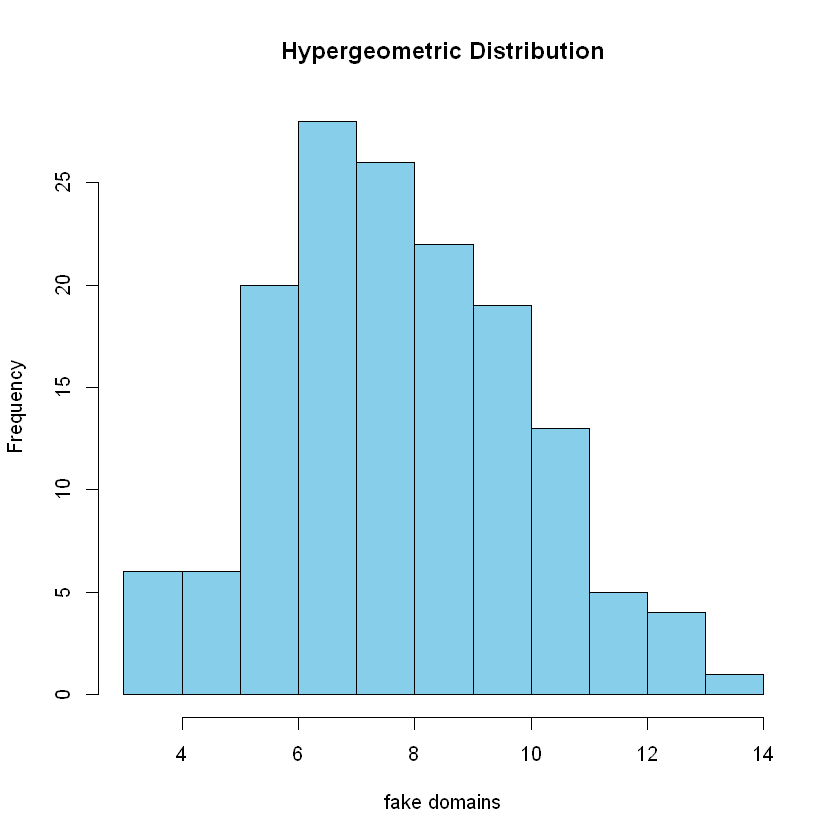

In [58]:
# In the name of god...
N <- 100  
k <- 20       
m <- 40
n <- 150
set.seed(532)
temp <- rhyper(n, k, N - k, m)
par(bg="white")
hist(temp, breaks = 15, main = "Hypergeometric Distribution", col = "skyblue", xlab = "fake domains")


In this part of the question, we modeled the number of fraudulent selected areas using hypergeometric distribution. The graph shows how the probability of identifying a certain number of fraudulent areas in the selected sample is distributed.

part B

In [ ]:
get_var_mean <- function(N, k, m, n_s) {
  for (n in seq(100, 10000, by = 50)) {
    p <- k / N
    mean_theory <- m * p
    var_theory <- m * p * (1 - p) * (N - m) / (N - 1)
    temp <- rhyper(n, m, N - m, k)
    mean_simulated <- mean(temp)
    var_simulated <- var(temp)
    cat("n:", n, "  mean_theory:", mean_theory, 
        "  var_theory:", var_theory, 
        "  mean_simulated:", mean_simulated, 
        "  var_simulated:", var_simulated, "\n")
  }
}
set.seed(532)
N <- 100
k <- 20
m <- 40
n_s <- seq(100, 10000, by = 50)
get_var_mean(N, k, m, n_s)


n: 100   mean_theory: 8   var_theory: 3.878788   mean_simulated: 8.38   var_simulated: 4.823838 
n: 150   mean_theory: 8   var_theory: 3.878788   mean_simulated: 7.953333   var_simulated: 4.528009 
n: 200   mean_theory: 8   var_theory: 3.878788   mean_simulated: 8.135   var_simulated: 3.65505 
n: 250   mean_theory: 8   var_theory: 3.878788   mean_simulated: 7.792   var_simulated: 3.932466 
n: 300   mean_theory: 8   var_theory: 3.878788   mean_simulated: 8.06   var_simulated: 3.648562 
n: 350   mean_theory: 8   var_theory: 3.878788   mean_simulated: 8.197143   var_simulated: 4.14727 
n: 400   mean_theory: 8   var_theory: 3.878788   mean_simulated: 7.8875   var_simulated: 4.090069 
n: 450   mean_theory: 8   var_theory: 3.878788   mean_simulated: 8.062222   var_simulated: 3.809037 
n: 500   mean_theory: 8   var_theory: 3.878788   mean_simulated: 8.034   var_simulated: 3.684212 
n: 550   mean_theory: 8   var_theory: 3.878788   mean_simulated: 7.909091   var_simulated: 3.933433 
n: 600   me

We know that in the hypergeometric distribution, the mean is equal to m*p and the value of p itself is also equal to k/N.
also the variance is equal to m*p*(1-p)*(N-m)/(N-1).
In the practical method, we modeled using the rhyper function and calculated the mean and variance values ​​for each sample from 100 to 10000 using prepared functions and printed the results.

part C


    n mean_theory var_theory mean_simulated var_simulated
1 100           8   3.878788       8.380000      4.823838
2 150           8   3.878788       7.953333      4.528009
3 200           8   3.878788       8.135000      3.655050
4 250           8   3.878788       7.792000      3.932466
5 300           8   3.878788       8.060000      3.648562
6 350           8   3.878788       8.197143      4.147270


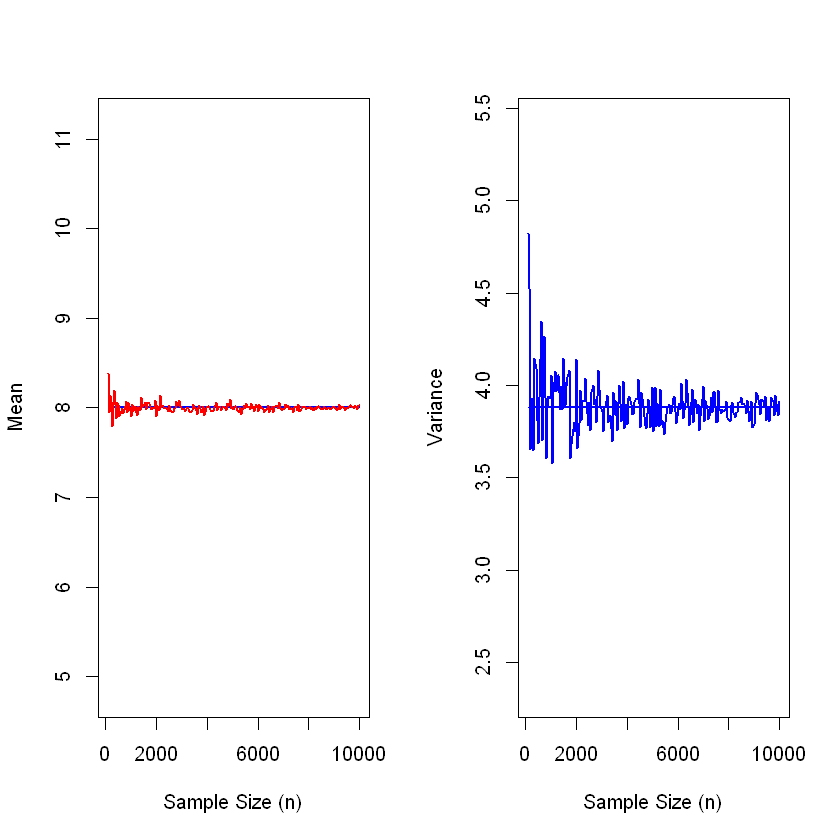

In [37]:
get_var_mean <- function(N, k, m, n_s) {
  results_list <- list()
  for (n in seq(100, 10000, by = 50)) {
    p <- k / N
    mean_theory <- m * p
    var_theory <- m * p * (1 - p) * (N - m) / (N - 1)
    temp <- rhyper(n, m, N - m, k)
    mean_simulated <- mean(temp)
    var_simulated <- var(temp)
    results_list[[length(results_list) + 1]] <- list(n = n, 
          mean_theory = mean_theory,    
          var_theory = var_theory, 
          mean_simulated = mean_simulated, 
          var_simulated = var_simulated)
  }
  results <- do.call(rbind, lapply(results_list, as.data.frame))
  return(results)
}
set.seed(532)
N <- 100
k <- 20
m <- 40
n_s <- seq(100, 10000, by = 50)
results <- get_var_mean(N, k, m, n_s)
print(head(results))
par(bg="white",mfrow = c(1, 2))
plot(results$n, results$mean_theory, type = "l", col = "blue", 
     xlab = "Sample Size (n)", ylab = "Mean", lwd = 2)
lines(results$n, results$mean_simulated, col = "red", lwd = 2)
plot(results$n, results$var_theory, type = "l", col = "blue", 
     xlab = "Sample Size (n)", ylab = "Variance", lwd = 2)
lines(results$n, results$var_simulated, col = "blue", lwd = 2)


From the graph, we can conclude that the more samples we use in modeling, the lower the percentage of error and the closer we get to the real value.

part D

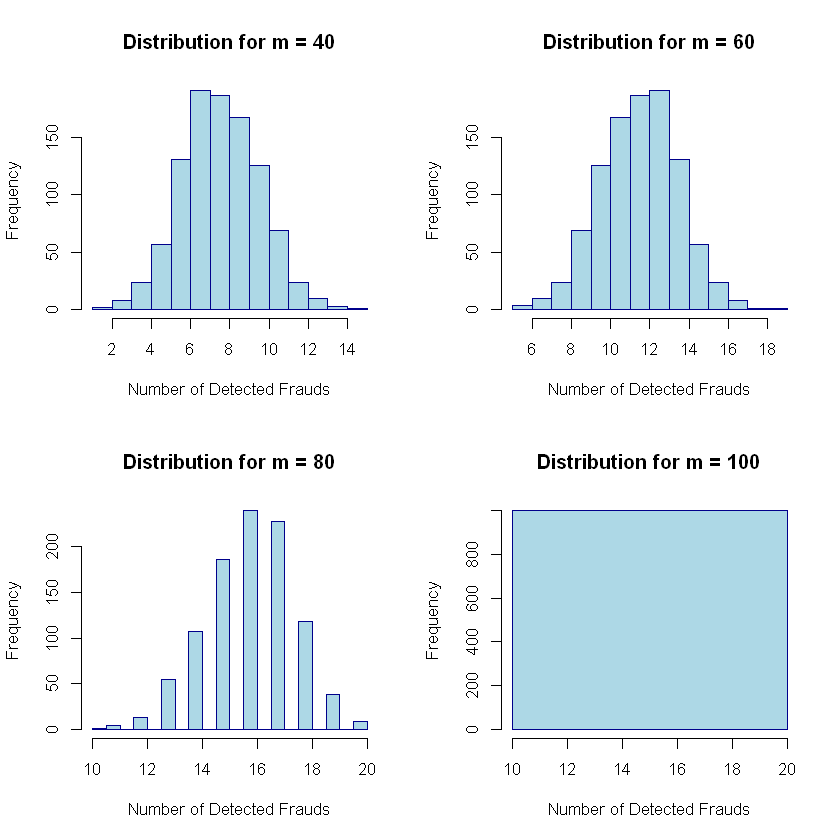

In [64]:
N <- 100
k <- 20
n <- 1000
m_values <- c(40, 60, 80, 100)
simulated_data <- list()
for (m in m_values) {
  set.seed(532)
  samples <- rhyper(n, m, N - m, k)
  simulated_data[[paste("m=", m)]] <- samples
}
par(bg="white", mfrow = c(2, 2))
for (m in m_values) {
  hist(simulated_data[[paste("m=", m)]],
       breaks = 15, col = "lightblue", border = "darkblue",
       main = paste("Distribution for m =", m),
       xlab = "Number of Detected Frauds", ylab = "Frequency")
}

If M = 40, the distribution is leans towards lower values ​​because the number of observations is limited.
The dispersion is low and the number of frauds detected will be close to the mean in most samples. And as m gets closer to 100, the distribution converges to a point near k=20, because all domains have been checked and the number of frauds is well known.
This distribution has the least dispersion (due to absolute confidence in the data).

part E

In [48]:
bin <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
hg <- function(N, k, n, x) {
  numerator <- choose(k, x) * choose(N - k, n - x)
  denominator <- choose(N, n)
  return(numerator / denominator)
}
N <- 100
k <- 20
n <- 20
p <- k / N
x_s <- 0:20
pmf1_list <- list()
for (i in 1:length(x_s))
  pmf1_list[[i]] <- bin(x_s[i], n, p)
pmf1 <- unlist(pmf1_list)
pmf2_list <- list()
for (i in 1:length(x_s))
  pmf2_list[[i]] <- hg(N, k, n, x_s[i])
pmf2 <- unlist(pmf2_list)
print("Binomial Distribution:")
print(pmf1)
print("Hypergeometric Distribution:")
print(pmf2)


[1] "Binomial Distribution:"
 [1] 1.152922e-02 5.764608e-02 1.369094e-01 2.053641e-01 2.181994e-01
 [6] 1.745595e-01 1.090997e-01 5.454985e-02 2.216088e-02 7.386959e-03
[11] 2.031414e-03 4.616849e-04 8.656592e-05 1.331783e-05 1.664729e-06
[16] 1.664729e-07 1.300570e-08 7.650410e-10 3.187671e-11 8.388608e-13
[21] 1.048576e-14
[1] "Hypergeometric Distribution:"
 [1] 6.595944e-03 4.325209e-02 1.259194e-01 2.158618e-01 2.436877e-01
 [6] 1.919510e-01 1.090630e-01 4.557859e-02 1.415952e-02 3.283368e-03
[11] 5.675536e-04 7.267012e-05 6.812823e-06 4.594528e-07 2.173088e-08
[16] 6.953880e-10 1.429663e-11 1.747487e-13 1.120184e-15 2.985167e-18
[21] 1.865730e-21


in this section, we implement the functions of hg and bin with dhyper and dbinom

part F

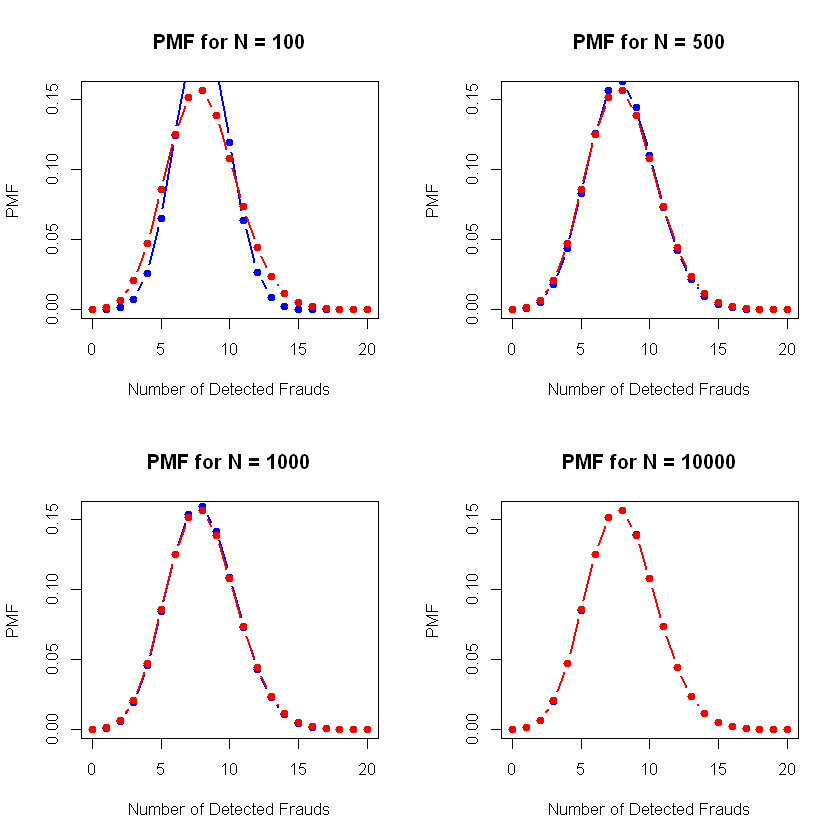

In [58]:
bin <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
hg <- function(N, k, n, x) {
  numerator <- choose(k, x) * choose(N - k, n - x)
  denominator <- choose(N, n)
  return(numerator / denominator)
}
k <- 20
m <- 40
n <- 40
x_s <- 0:20
N_values <- c(100, 500, 1000, 10000)
par(mfrow = c(2, 2), bg = "white")
for (N in N_values) {
  k <- N / 5
  p <- k / N
  pmf1_list <- list()
  for (i in 1:length(x_s))
    pmf1_list[[i]] <- bin(x_s[i], n, p)
  pmf1 <- unlist(pmf1_list)
  pmf2_list <- list()
  for (i in 1:length(x_s))
    pmf2_list[[i]] <- hg(N, k, n, x_s[i])
  pmf2 <- unlist(pmf2_list)
  plot(x_s, pmf2, type = "b", col = "blue", pch = 19, lwd = 2,
       main = paste("PMF for N =", N),
       xlab = "Number of Detected Frauds", ylab = "PMF",
       ylim = c(0, max(c(pmf_bin, pmf_hg))))
  lines(x_s, pmf1, type = "b", col = "red", pch = 19, lwd = 2)
}


part G

When asked about the project, it was also mentioned that binomial and hypergeometric distributions become closer to each other as n increases. Now why? This is because we said that hypergeometric distribution is without substitution and binomial distribution with substitution and now we show that they are not different at infinity.
For n = 100: there is a significant difference between hypergeometric and binomial distributions.
The hypergeometric distribution is narrower and has higher values ​​around the median.
The binomial distribution is wider.
Reason: The effect of non-nesting sampling is more evident in the hypergeometric distribution because the population is small and the probability of changes in the distribution is greater.
For n = 200: the difference between the two distributions is reduced, but still detectable.
Binomial and hypergeometric distributions have become closer together.
Reason: As the population increases, the effect of sampling without placement decreases and the probability of each selection becomes approximately independent.
For n = 500 the two distributions are almost identical.
The overall shape and PMF values ​​are very close.
Reason: The population is so large that the effect of sampling without placement is almost eliminated and the hypergeometric distribution tends to the binomial distribution.
For n = 10,000, the two distributions practically overlap completely.
Binomial and hypergeometric graphs look the same.
Reason: With a very large population, the hypergeometric distribution theoretically becomes a binomial distribution (according to the theory).
So, we conclude that with the increase of 𝑁, the hypergeometric distribution approaches the binomial distribution. This is also clearly seen in the graphs.
Now, in order for the number of frauds to increase proportionally to the population, we take k = N/5

QUESTION 2

part A

In [85]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, m, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, m, p)))
}
N <- 1000
p <- 450/N
x <- 430
cdf_binomial <- bin_cdf(x, N, p)
cat("Binomial CDF (x <= ", x, "): ", cdf_binomial, "\n")


Binomial CDF (x <=  430 ):  0.1074638 


In this, we get the value of cdf by dividing with the sum of 430 the value of pmf that we calculated

part B

In [78]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, m, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, m, p)))
}
normal_cdf <- function(x, mu, sigma) {
  pnorm(x, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
x <- 430
binomial_cdf_result <- bin_cdf(x, N, p)
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
normal_cdf_result <- normal_cdf(x, mu, sigma) 
relative_error <- abs(binomial_cdf_result - normal_cdf_result) 
cat("Binomial CDF:", binomial_cdf_result, "\n")
cat("Normal CDF (without continuity correction):", normal_cdf_result, "\n")
cat("Relative Error:", relative_error, "\n")


Binomial CDF: 0.1074638 
Normal CDF (without continuity correction): 0.1018139 
Relative Error: 0.005649884 


part C

In [79]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, m, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, m, p)))
}
normal_cdf <- function(x, mu, sigma) {
  pnorm(x, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
x <- 430.5
binomial_cdf_result <- bin_cdf(x, N, p)
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
normal_cdf_result <- normal_cdf(x, mu, sigma) 
relative_error <- abs(binomial_cdf_result - normal_cdf_result) 
cat("Binomial CDF:", binomial_cdf_result, "\n")
cat("Normal CDF (without continuity correction):", normal_cdf_result, "\n")
cat("Relative Error:", relative_error, "\n")


Binomial CDF: 0.1074638 
Normal CDF (without continuity correction): 0.1075799 
Relative Error: 0.0001161443 


part D

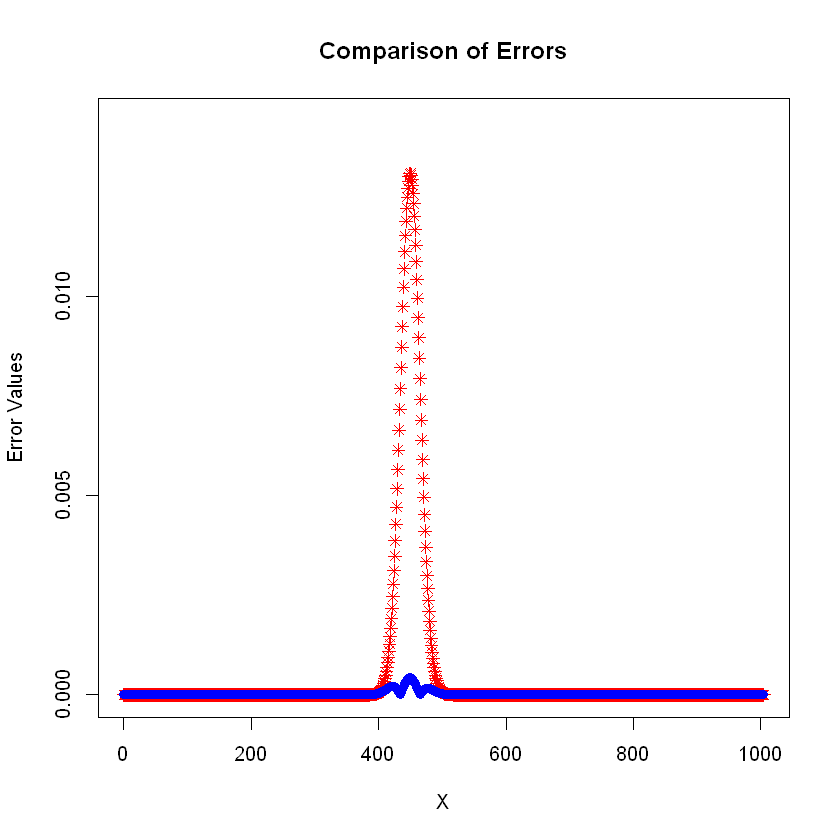

In [63]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, n, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, n, p)))
}
normal_cdf1 <- function(x, mu, sigma) {
  pnorm(x + 0.5, mean = mu, sd = sigma)
}
normal_cdf2 <- function(x, mu, sigma) {
  pnorm(x, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
x_values <- seq(0, 1005)
bin_values <- list()
normal_values1 <- list()
normal_values2 <- list()
error_values1 <- list()
error_values2 <- list()
for (x in x_values) {
  bin <- bin_cdf(x, N, p)
  normal1 <- normal_cdf1(x, mu, sigma)
  normal2 <- normal_cdf2(x, mu, sigma)
  error1 <- abs(bin - normal1)
  error2 <- abs(bin - normal2)
  bin_values <- c(bin_values, bin)
  normal_values1 <- c(normal_values1, normal1)
  normal_values2 <- c(normal_values2, normal2)
  error_values1 <- c(error_values1, error1)
  error_values2 <- c(error_values2, error2)
}
bin_values <- unlist(bin_values)
normal_values1 <- unlist(normal_values1)
normal_values2 <- unlist(normal_values2)
error_values1 <- unlist(error_values1)
error_values2 <- unlist(error_values2)
max_error <- max(c(error_values1, error_values2))
par(bg = "white")
plot(x_values, error_values2, type = "b", col = "red", pch = 8, lwd = 1,
     main = "Comparison of Errors",
     xlab = "X", ylab = "Error Values",
     ylim = c(0, max_error * 1.1))
lines(x_values, error_values1, type = "b", col = "blue", pch = 19, lwd = 1)



The blue curve (with continuity correction) always has a smaller error than the red curve (without continuity correction). Continuity correction significantly reduces the error of the normal approximation, especially at values ​​near the end of the interval.

part E

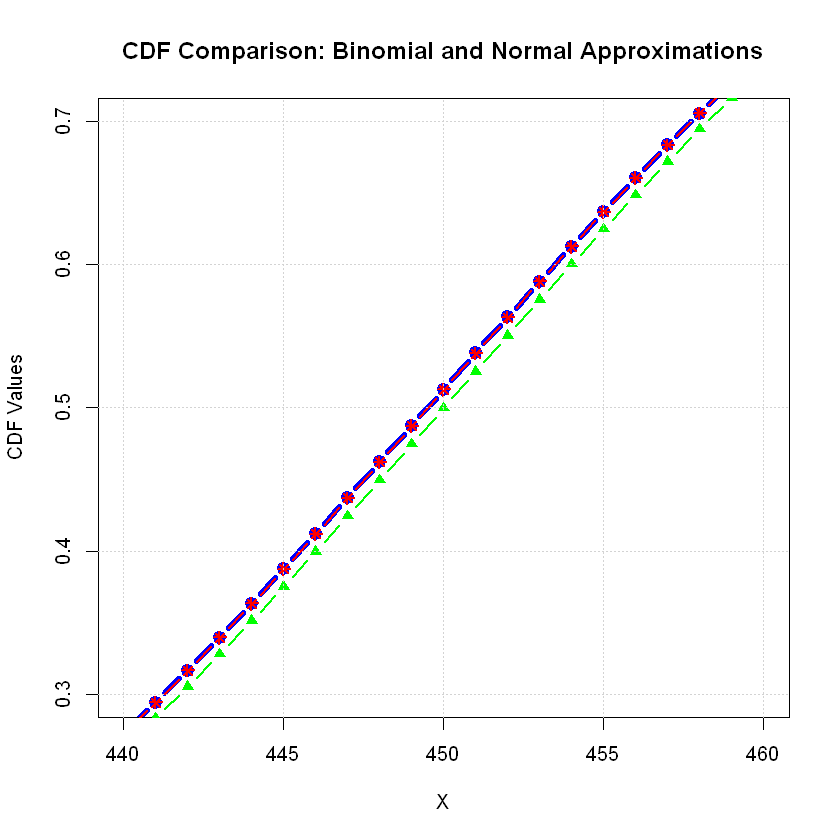

In [ ]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, n, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, n, p)))
}
normal_cdf1 <- function(x, mu, sigma) {
  pnorm(x + 0.5, mean = mu, sd = sigma)
}
normal_cdf2 <- function(x, mu, sigma) {
  pnorm(x, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
x_values <- seq(440, 460)
bin_values <- list()
normal_values1 <- list()
normal_values2 <- list()
for (x in x_values) {
  bin_values <- c(bin_values, bin_cdf(x, N, p))
  normal_values1 <- c(normal_values1, normal_cdf1(x, mu, sigma))
  normal_values2 <- c(normal_values2, normal_cdf2(x, mu, sigma))
}
bin_values <- unlist(bin_values)
normal_values1 <- unlist(normal_values1)
normal_values2 <- unlist(normal_values2)
par(bg = "white")
plot(x_values, bin_values, type = "b", col = "blue", pch = 19, lwd = 5,
     main = "CDF Comparison: Binomial and Normal Approximations",
     xlab = "X", ylab = "CDF Values",
     ylim = c(0.3, 0.7))
     
lines(x_values, normal_values1, type = "b", col = "red", pch = 8, lwd = 2)
lines(x_values, normal_values2, type = "b", col = "green", pch = 17, lwd = 2)


The red line (normal approximation with continuity correction) is very close to the blue line. This indicates that the use of continuity correction reduces the error caused by the discreteness of the binomial distribution. The green line (normal approximation without continuity correction) is slightly more distant from the blue line, which concludes that we have less error with the continuity correction and the binomial distribution We are getting closer

part F

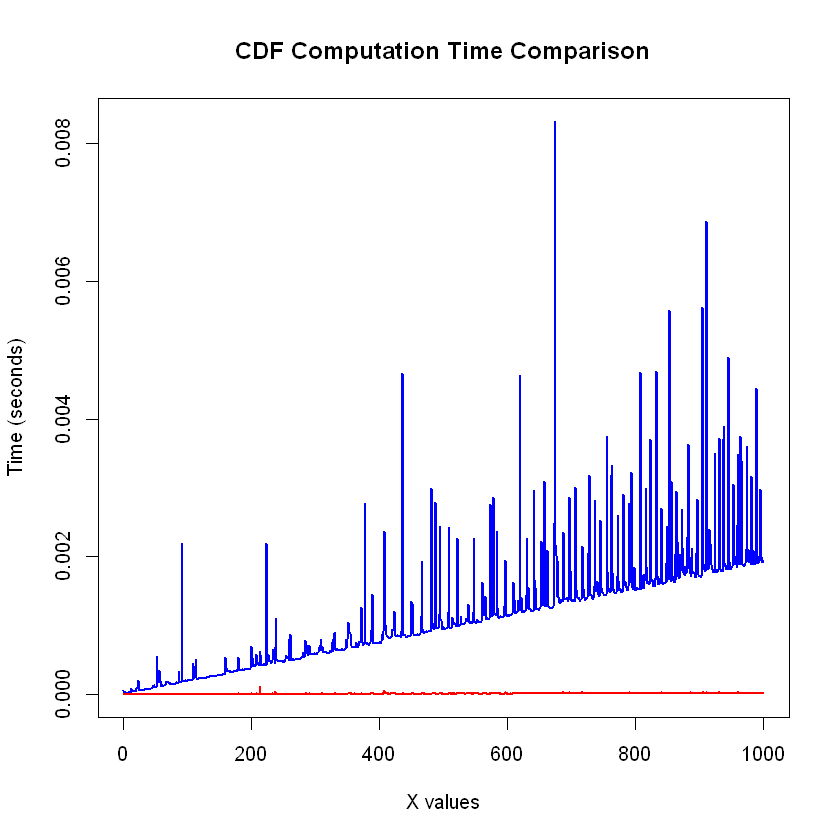

In [142]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, n, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, n, p)))
}
normal_cdf1 <- function(x, mu, sigma) {
  pnorm(x + 0.5, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
x_values <- seq(0, N)
bin_values <- list()
normal_values <- list()
bin_times <- list()
normal_times <- list()
for (x in x_values) {
  start_bin <- Sys.time()
  bin_values <- c(bin_values, bin_cdf(x, N, p))
  end_bin <- Sys.time()
  start_normal <- Sys.time()
  normal_values <- c(normal_values, normal_cdf1(x, mu, sigma))
  end_normal <- Sys.time()
  bin_times <- c(bin_times, abs(start_bin - end_bin))
  normal_times <- c(normal_times, abs(start_normal - end_normal))
}
bin_values <- unlist(bin_values)
normal_values <- unlist(normal_values)
bin_times <- unlist(bin_times)
normal_times <- unlist(normal_times)
par(bg = "white", mfrow = c(1, 1))
plot(0:1000, bin_times, type = "l", col = "blue", lwd = 2, 
     xlab = "X values", ylab = "Time (seconds)", 
     main = "CDF Computation Time Comparison",
     ylim = c(0, max(c(bin_times, normal_times))), xlim = c(0, 1000))
lines(0:1000, normal_times, col = "red", lwd = 2)


We can see that for the binomial distribution (blue line) compared to the normal distribution (red line), the calculation time is more. This is because computing the CDF for the binomial distribution directly requires computing the sum of the various terms for all values ​​of x, while computing the CDF for the normal distribution only requires the use of the cumulative normal function, which can be computed analytically. The binomial distribution requires more time to calculate the CDF, especially for high values ​​of x, which is due to the greater complexity of the calculations.
The normal distribution using the normal cumulative function and continuity correction takes less computation time and can provide a good approximation of the CDF of the binomial distribution at large scales.
Consequently, it will be more efficient to use the normal distribution in situations where the binomial distribution is for large N and p is close to 0.5.

part G

In [226]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, n, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, n, p)))
}
normal_cdf1 <- function(x, mu, sigma) {
  pnorm(x + 0.5, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
x_values <- seq(400, 600)
bin_values <- list()
normal_values <- list()
bin_times <- list()
normal_times <- list()
for (x in x_values) {
  start_bin <- Sys.time()
  bin_values <- c(bin_values, bin_cdf(x, N, p))
  end_bin <- Sys.time()
  start_normal <- Sys.time()
  normal_values <- c(normal_values, normal_cdf1(x, mu, sigma))
  end_normal <- Sys.time()
  bin_times <- c(bin_times, abs(start_bin - end_bin))
  normal_times <- c(normal_times, abs(start_normal - end_normal))
}
bin_values <- unlist(bin_values)
normal_values <- unlist(normal_values)
bin_times <- unlist(bin_times)
normal_times <- unlist(normal_times)
ans <- list()
for(i in 400:600)
   if(abs(bin_values[i - 399] - normal_values[i - 399]) * 1000000 < abs(bin_times[i - 399] - normal_times[i - 399]) * 100)
        ans <- c(ans, i)
print(ans[1])

[[1]]
[1] 524



part H

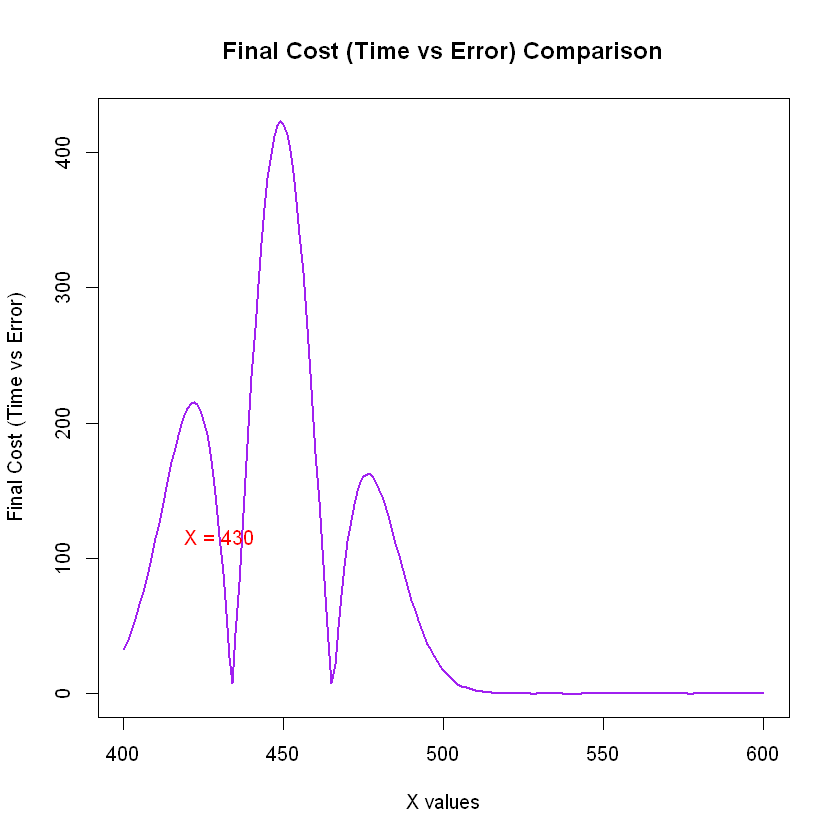

In [77]:
bin_pmf <- function(x, n, p) {
  if (x > n || x < 0) {
    return(0)
  }
  choose(n, x) * (p^x) * ((1 - p)^(n - x))
}
bin_cdf <- function(x, n, p) {
  sum(sapply(0:x, function(i) bin_pmf(i, n, p)))
}
normal_cdf1 <- function(x, mu, sigma) {
  pnorm(x + 0.5, mean = mu, sd = sigma)
}
N <- 1000
p <- 450 / N
mu <- N * p
var <- N * p * (1 - p)
sigma <- sqrt(var)
x_values <- seq(400, 600)
bin_values <- list()
normal_values <- list()
bin_times <- list()
normal_times <- list()
for (x in x_values) {
  start_bin <- Sys.time()
  bin_values <- c(bin_values, bin_cdf(x, N, p))
  end_bin <- Sys.time()
  start_normal <- Sys.time()
  normal_values <- c(normal_values, normal_cdf1(x, mu, sigma))
  end_normal <- Sys.time()
  bin_times <- c(bin_times, abs(start_bin - end_bin))
  normal_times <- c(normal_times, abs(start_normal - end_normal))
}
bin_values <- unlist(bin_values)
normal_values <- unlist(normal_values)
bin_times <- unlist(bin_times)
normal_times <- unlist(normal_times)
ans <- list()
for(i in 400:600)
   ans <- c(ans, abs(bin_values[i - 399] - normal_values[i - 399]) * 1000000 - abs(bin_times[i - 399] - normal_times[i - 399]) * 100)
par(bg = "white")
plot(x_values, unlist(ans), type = "l", col = "purple", lwd = 2,
     xlab = "X values", ylab = "Final Cost (Time vs Error)",
     main = "Final Cost (Time vs Error) Comparison")
x_430 <- 430
ans_at_430 <- ans[[x_430 - 399]]
text(x_430, ans_at_430, labels = "X = 430", col = "red")

According to the obtained graph, for each X, if the final cost is positive, it means it is cost-effective, and if it is negative, it is not cost-effective.
 Now, in the graph obtained at X = 430, the number of the graph is positive, so it is cost-effective

QUESTION 3

part A

In [ ]:
time <- 8
mean_time <- 0.25
cnt <- time / mean_time
lambda <- 1 / mean_time
exp <- function(cnt, lambda) {
  rexp(cnt, lambda)
}
samples <- exp(cnt, lambda)
samples

[1] 0.93554611 0.10694514 0.49851499 0.89053814 0.59459278 0.82912428
 [7] 0.18968967 0.22184149 0.24777966 0.33813370 0.12090783 0.19442970
[13] 0.10887230 0.11371472 0.38445819 0.95545246 1.39315635 0.11865647
[19] 0.29824037 0.06134300 0.08150943 0.64324613 0.14676186 0.03411285
[25] 0.59350910 0.13006584 0.52278331 0.11316246 0.06960030 0.04105665
[31] 0.48517506 0.40419334

part B

In [30]:
time <- 8
mean_time <- 0.25
cnt <- time / mean_time
lambda <- 1 / mean_time
MAXtime <- 12/60
exp <- function(cnt, lambda) {
  rexp(cnt, rate = lambda)
}
samples <- exp(cnt, lambda)
after_12 <- function(samples, MAXtime) {
    result <- c()
    for (i in 1:length(samples))
        if (samples[i] <= 8 && samples[i] > MAXtime)
            result <- c(result, samples[i] - MAXtime)
  return(result)
}
ans <- after_12(samples, MAXtime)
ans

[1] 0.14430234 0.41565075 0.09954843 0.18642731 0.25022379 0.03463992
 [7] 0.01179879 0.33803502 0.74507160 0.31550136 0.06889980 0.55654766
[13] 0.11212814 0.15629844

part C

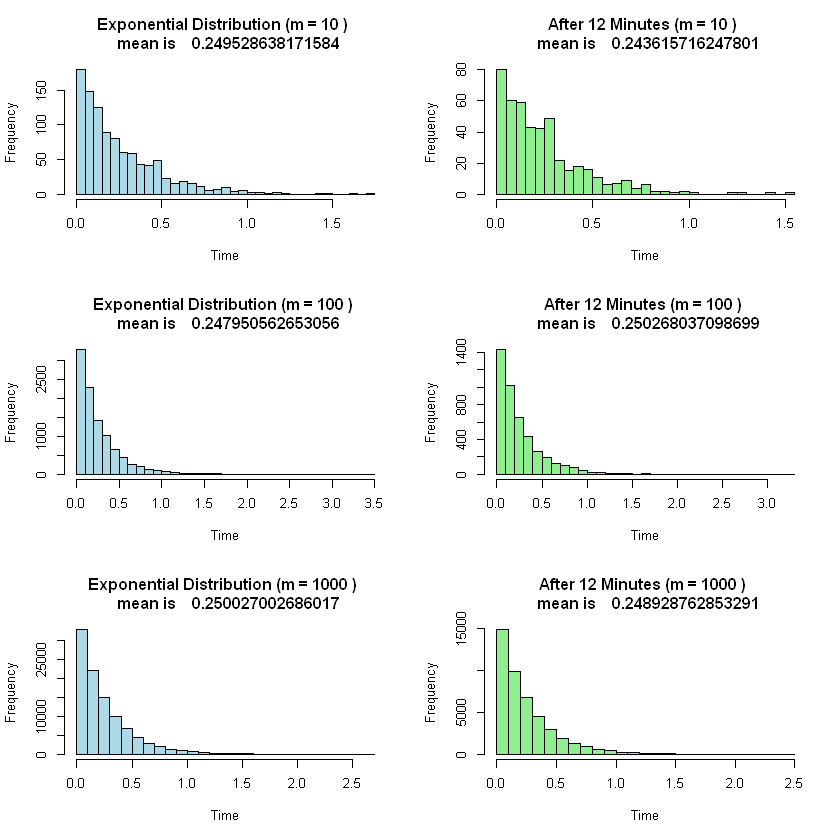

In [40]:
mean_time <- 0.25
lambda <- 1 / mean_time
MAXtime <- 12 / 60
exp <- function(n, lambda) {
  rexp(n, rate = lambda)
}
after_12 <- function(samples, MAXtime) {
  result <- c()
  for (i in 1:length(samples)) {
    if (samples[i] <= 8 && samples[i] > MAXtime) {
      result <- c(result, samples[i] - MAXtime)
    }
  }
  return(result)
}
m_values <- c(10, 100, 1000)
par(mfrow = c(3, 2), bg = "white")
for (m in m_values) {
  exp_samples <- exp(m * 100, lambda)
  after_12_samples <- after_12(exp_samples, MAXtime)
  mean_exp <- mean(exp_samples)
  mean_after_12 <- mean(after_12_samples)
  hist(exp_samples, main = paste("Exponential Distribution (m =", m, ")", "\n  mean is   ",mean_exp), 
       xlab = "Time", col = "lightblue", breaks = 30)
  hist(after_12_samples, main = paste("After 12 Minutes (m =", m, ")", "\n  mean is   ",mean_after_12), 
       xlab = "Time", col = "lightgreen", breaks = 30)
}


Note that because I took the lambda in terms of hours, the average obtained is almost 0.25, and if we want to convert it to minutes, we have to multiply it by 60.
Now, by comparing these two graphs, we can conclude that the average obtained for both cases is almost equal to 0.25.

part D

Given the memoryless property of the exponential distribution observed in this simulation, this assumption is rejected. Because in the exponential distribution, even if a long time has passed since the customer entered the store, the probability of a new customer entering the store in the future (after 12 minutes or more) is the same as if the customer had not entered the store. Store Entered Store Consequently, non-retention means that the prediction of new customer arrivals is not affected by past time.
As a result, we conclude from this simulation that it is irrelevant that if someone does not arrive by minute 12, it is more likely that they will arrive later, which is the explanation of the memoryless exponential distribution.

part E

In [11]:
mean_time <- 0.25
lambda <- 1 / mean_time
MAXtime <- 12 / 60
time_after_15 <- 15 / 60
exp <- function(n, lambda) {
  rexp(n, rate = lambda)
}
after_12_and_15 <- function(samples, MAXtime, time_after_15) {
  result <- c()
  for (i in 1:length(samples)) {
    if (samples[i] > MAXtime && samples[i] <= 8) {
      if (samples[i] > MAXtime + time_after_15) {
        result <- c(result, samples[i] - MAXtime)
      }
    }
  }
  return(result)
}
m <- 1000
exp_samples <- exp(m * 100, lambda)
after_12_15_samples <- after_12_and_15(exp_samples, MAXtime, time_after_15)
probability_simulation <- length(after_12_15_samples) / length(exp_samples)
print(1 - probability_simulation)


exp_theory <- pexp(((time_after_15 - MAXtime) * 60), 1 / (mean_time * 60))
1 - exp_theory

[1] 0.83393


[1] 0.8187308

QUESTION 4

part A

In [40]:
exp <- function(n) {
  (runif(n, 0, 1))
}
n <- 1000000
lambda <- 1 / 2
ans <- exp(n)
ans

[1] 1.045914e-01 8.519596e-01 9.498356e-01 3.749944e-01 1.293307e-01
    [6] 7.829494e-01 4.544933e-01 2.454116e-01 2.837470e-01 7.968246e-02
   [11] 9.221833e-01 7.393701e-01 6.754174e-01 4.565565e-01 2.668045e-02
   [16] 4.317122e-01 4.354605e-01 2.248704e-01 8.237553e-02 8.666224e-02
   [21] 9.272226e-01 3.315499e-01 8.278153e-01 1.479110e-01 4.848985e-01
   [26] 4.182847e-01 3.285294e-01 3.625153e-01 1.480990e-01 2.850712e-01
   [31] 9.898485e-01 4.670778e-01 8.206852e-01 4.890146e-01 4.470225e-01
   [36] 5.352452e-01 7.294268e-01 3.293769e-01 9.747671e-01 1.424226e-01
   [41] 5.600800e-01 1.751107e-02 5.448205e-01 1.251999e-01 3.388524e-01
   [46] 1.121570e-01 3.902432e-01 7.596557e-01 7.457777e-01 2.822342e-01
   [51] 8.950369e-01 4.032263e-01 2.239108e-01 7.631436e-01 4.375131e-01
   [56] 9.356992e-01 3.576580e-01 1.126128e-01 5.495914e-01 6.881809e-01
   [61] 8.489754e-01 5.440833e-01 8.183495e-01 9.580920e-01 7.835835e-01
   [66] 6.103380e-01 8.348180e-01 8.218389e-01 7.534867e-01 2.552716e-01
   [71] 6.867173e-01 4.353241e-01 4.938708e-01 5.202639e-01 9.157837e-01
   [76] 4.981721e-01 7.990625e-01 3.028175e-01 5.036032e-01 6.861981e-01
   [81] 9.680465e-01 8.685613e-02 7.120866e-01 1.899037e-02 2.165361e-01
   [86] 2.629807e-01 3.166228e-01 5.557596e-03 7.905893e-01 5.852678e-01
   [91] 5.491121e-01 9.420442e-01 7.957359e-01 6.938440e-01 3.759096e-01
   [96] 2.984453e-01 9.458290e-01 4.364445e-01 2.588674e-01 8.429222e-01
  [101] 9.740232e-01 9.993724e-01 1.775384e-01 1.184254e-01 2.754031e-01
  [106] 2.159053e-01 4.260308e-01 3.213445e-01 6.530727e-01 1.102901e-01
  [111] 5.491071e-01 9.797228e-01 6.347302e-01 3.526568e-01 2.407467e-01
  [116] 9.104228e-01 9.466068e-01 7.575871e-02 9.712183e-01 1.909069e-01
  [121] 5.000722e-01 1.222955e-01 4.363721e-01 7.484701e-01 9.274893e-01
  [126] 5.245334e-01 6.328018e-01 4.635046e-01 3.823610e-01 7.442617e-01
  [131] 6.761778e-01 4.057461e-01 4.453479e-01 5.737731e-01 6.354684e-01
  [136] 9.824035e-01 3.408334e-01 4.149868e-01 6.595467e-01 1.867647e-01
  [141] 1.577508e-01 1.356606e-01 2.752954e-02 2.665188e-01 1.276705e-01
  [146] 1.296754e-01 1.708145e-01 5.488748e-01 9.121398e-01 3.240820e-01
  [151] 4.681713e-01 2.676833e-01 5.653028e-01 1.742118e-03 8.458810e-01
  [156] 3.901693e-01 7.628904e-01 7.927560e-01 2.342924e-01 7.844466e-01
  [161] 6.880395e-01 8.101784e-01 5.313889e-01 7.445922e-01 1.094557e-01
  [166] 2.965668e-01 1.098366e-01 5.413685e-01 6.619087e-01 2.810549e-03
  [171] 8.516487e-01 6.080580e-01 4.683509e-02 1.355151e-01 2.957608e-01
  [176] 7.829781e-01 1.736007e-01 2.238279e-01 2.369533e-01 7.916503e-01
  [181] 5.470568e-01 9.917993e-01 1.667839e-01 5.147239e-01 8.323028e-01
  [186] 2.991514e-01 3.887918e-01 1.489029e-01 8.313115e-01 7.664442e-01
  [191] 5.005234e-01 7.649847e-01 2.921459e-01 4.867829e-01 2.755118e-01
  [196] 2.451211e-01 5.378575e-01 1.788543e-01 7.588335e-01 3.938232e-01
  [201] 4.047293e-01 5.997745e-01 3.923595e-01 6.780178e-01 9.139745e-01
  [206] 9.183075e-01 8.595347e-02 9.979074e-01 7.857554e-01 8.784017e-01
  [211] 9.579821e-01 6.250348e-01 8.886865e-01 2.740525e-01 3.303141e-01
  [216] 9.688658e-01 3.830582e-01 6.626202e-01 4.997539e-01 8.399193e-02
  [221] 2.460540e-01 2.720513e-01 2.372057e-01 2.045438e-01 4.518272e-01
  [226] 5.221397e-01 2.400046e-01 4.773961e-01 7.758347e-01 4.169658e-01
  [231] 2.343392e-01 2.286440e-01 8.748284e-01 6.280388e-01 8.125142e-01
  [236] 7.698776e-01 9.495695e-01 4.822625e-01 2.233264e-01 1.722917e-01
  [241] 3.918867e-02 5.464528e-01 7.363706e-01 5.006027e-01 9.868232e-01
  [246] 7.291442e-01 2.474830e-01 9.589147e-01 2.110598e-01 6.735023e-01
  [251] 3.524617e-01 4.083135e-01 5.829942e-01 3.545079e-01 3.297096e-04
  [256] 1.029376e-01 6.456919e-01 5.922079e-01 6.692440e-01 9.755699e-01
  [261] 2.010602e-01 5.151175e-01 4.309915e-01 3.390591e-01 4.623604e-01
  [266] 6.239362e-02 1.131866e-01 2.216201e-01 7.130588e-01 8.110271e-02
  [271] 9.990196e-01 2.150890e-01 1.072728e-02 3.989328e-01 5.

part B

In [41]:
exp <- function(n) {
  -2 * log(runif(n, 0, 1))
}
lambda <- 1 / 2
n = 1000000
ans <- exp(n)
ans

[1] 3.251576e+00 1.461260e+00 8.637270e-01 4.489399e-01 2.977425e-02
    [6] 1.215177e-01 4.026208e-01 2.347878e+00 2.609081e+00 1.896396e+00
   [11] 1.919116e-01 3.840982e+00 6.555229e+00 8.715348e-01 2.177458e+00
   [16] 1.882009e-01 1.259496e+00 2.843455e+00 4.534770e+00 1.605086e+00
   [21] 8.409776e-01 8.071857e-01 1.051308e+00 1.300848e+00 4.602592e+00
   [26] 1.427698e+00 4.303927e-01 1.542729e-01 4.793399e-01 1.833189e+00
   [31] 2.451540e+00 5.118454e-01 2.348337e+00 7.335589e-01 2.553465e-03
   [36] 1.248246e+00 9.345596e-01 6.746911e-01 7.073987e-01 1.598016e+00
   [41] 3.164459e-01 6.448007e-01 5.343984e-01 1.597270e+00 1.075016e+00
   [46] 5.391473e+00 1.698848e-01 3.429021e-01 3.540057e-01 9.234717e-01
   [51] 1.385385e+00 1.041242e+01 8.544635e-01 1.806535e+00 3.053571e+00
   [56] 1.266057e+00 3.239085e+00 3.604856e+00 4.300253e-01 1.158160e+00
   [61] 1.492592e+00 9.775417e-01 1.754849e+00 9.542266e+00 4.400334e-01
   [66] 6.152418e-01 9.915788e-01 1.200637e+00 1.350304e+00 2.580469e+00
   [71] 3.340020e+00 6.176043e+00 3.714935e+00 4.558097e+00 4.708002e+00
   [76] 1.206924e+00 1.205542e+00 5.585113e+00 1.826600e-01 2.785263e+00
   [81] 1.152579e-01 1.471213e+00 9.881420e+00 7.597907e-01 4.984498e+00
   [86] 1.560653e+00 7.023443e-01 4.913050e+00 2.943309e-01 2.939960e+00
   [91] 3.614285e+00 3.156774e+00 4.093810e-01 3.560330e-01 2.894303e+00
   [96] 2.211787e-01 9.056642e+00 6.691424e-01 3.776483e-01 2.849562e+00
  [101] 3.931364e-01 1.597839e+00 1.463992e+00 4.585592e-01 3.579522e-01
  [106] 7.599488e-02 2.344044e+00 1.661416e+00 5.180070e+00 4.297828e-01
  [111] 1.832174e+00 5.140521e-01 4.667227e-01 1.473652e+00 1.426252e+00
  [116] 1.233054e+00 3.194416e+00 1.587808e+00 6.098755e-01 8.930367e-01
  [121] 1.312093e+00 2.077861e+00 9.008646e+00 7.857815e-01 4.234448e+00
  [126] 8.515089e-01 3.011439e+00 1.270310e+00 1.923025e+00 8.415763e-01
  [131] 1.017539e+00 3.519710e-01 4.313082e+00 1.193431e+00 3.851038e-01
  [136] 1.022861e+00 2.328032e-01 3.586730e+00 9.082361e-02 4.079079e+00
  [141] 1.075759e+00 4.591988e-01 7.467154e-01 2.184552e+00 1.546212e+00
  [146] 4.256371e-01 3.600498e-01 3.627483e-02 3.852350e+00 1.349932e+00
  [151] 1.936103e+00 2.091512e+00 6.849855e-01 7.494441e-01 3.865300e+00
  [156] 7.067416e-01 7.056802e+00 1.091087e+00 1.386473e+00 2.785084e+00
  [161] 9.569286e-01 2.409172e+00 1.414969e+00 6.914268e-01 1.213643e-01
  [166] 1.188350e+00 9.815376e-01 2.480930e+00 6.056988e+00 3.783319e+00
  [171] 1.032985e+00 2.513745e+00 6.157171e+00 5.318998e-01 1.660587e+00
  [176] 1.832420e+00 1.303106e+00 1.317584e+00 1.712846e+00 7.847202e-01
  [181] 2.045013e+00 1.487857e+00 2.614822e+00 1.159299e+00 1.118359e+00
  [186] 1.965940e+00 4.032748e-01 6.236726e+00 1.409580e-01 1.852347e+00
  [191] 1.531581e-01 5.942546e-01 2.436782e+00 7.796859e-01 2.215211e+00
  [196] 6.210694e-01 4.893896e-01 1.889503e+00 6.126092e+00 1.006246e+00
  [201] 1.571988e-01 2.308832e+00 4.145724e+00 1.425342e+00 3.126619e-01
  [206] 4.676088e+00 6.963908e+00 1.976400e-02 1.002836e+00 1.377660e+00
  [211] 5.670172e+00 1.167852e+00 3.690387e+00 5.405325e-01 1.357919e+00
  [216] 2.232214e+00 1.911165e+00 8.495476e-01 6.569230e-01 3.642429e+00
  [221] 4.465706e+00 2.090149e+00 1.014660e+00 3.613743e+00 1.141846e+00
  [226] 3.023845e-01 9.648439e-01 4.949893e-01 8.574145e-01 3.163775e+00
  [231] 3.962242e+00 1.783900e-01 2.645237e+00 2.177989e+00 2.155334e+00
  [236] 1.576082e+00 2.935159e+00 1.467282e-01 4.239496e-01 2.572439e+00
  [241] 1.818849e+00 2.896868e-01 6.517235e-01 2.907295e+00 2.084774e-01
  [246] 9.088471e-01 1.837440e-01 3.750555e-01 2.492514e+00 4.169860e+00
  [251] 8.005018e-01 2.710407e+00 6.139683e-01 1.525803e+00 2.330576e+00
  [256] 4.060567e-01 1.335961e+00 6.582191e+00 3.265256e-01 1.087574e+00
  [261] 7.567347e-01 7.159096e-01 5.622962e-01 1.035483e+00 2.500796e-01
  [266] 7.561333e-01 9.435906e-01 2.927803e+00 3.188552e+00 1.439165e-01
  [271] 2.879161e+00 1.764371e+00 5.545812e+00 2.859300e+00 9.

part C

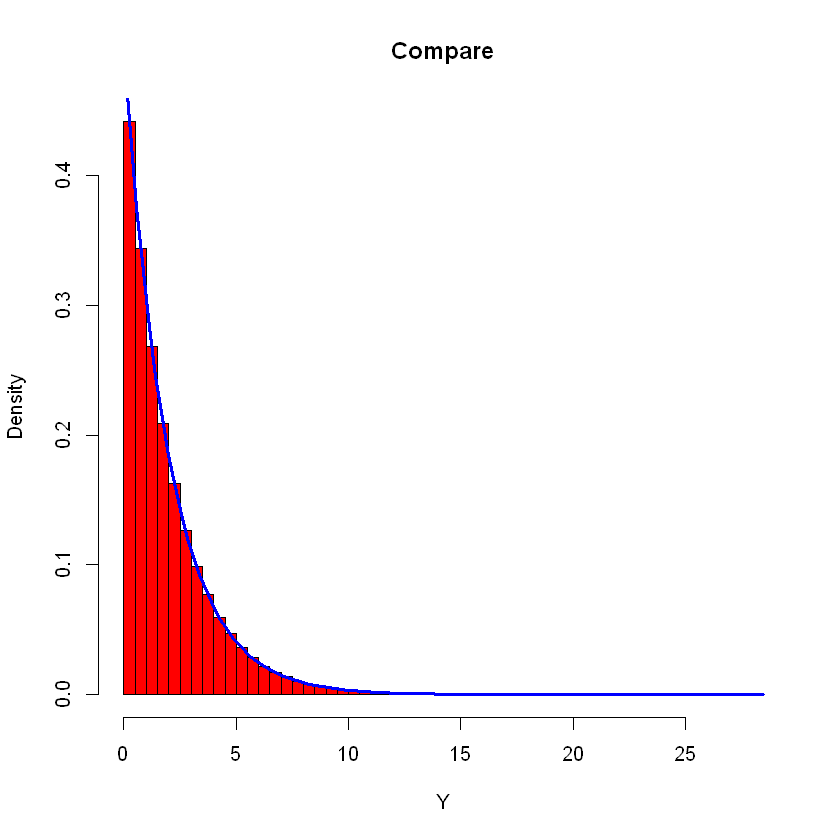

In [21]:
exp1 <- function(n) {
  runif(n, 0, 1)
}
exp2 <- function(n) {
  -2 * log(runif(n, 0, 1))
}
exp_density <- function(x, lambda) {
  lambda * exp(-lambda * x)
}
n <- 1000000
lambda <- 1 / 2
ans1 <- exp1(n)
ans2 <- exp2(n)
par(bg = "white")
hist(ans2, breaks = 100, probability = TRUE, col = "red", 
     main = "Compare", xlab = "Y", ylab = "Density")
curve(exp_density(x, lambda), add = TRUE, col = "blue", lwd = 3)


Considering the two graphs drawn, we can conclude that the simulation we performed corresponds to an exponential distribution.

part D

In [23]:

n <- 1000000
U1 <- runif(n, 0, 1)
U2 <- runif(n, 0, 1)
U1
U2

[1] 9.669815e-03 8.414812e-01 8.293029e-01 4.163659e-01 4.715788e-01
    [6] 6.754948e-01 8.789056e-01 5.865657e-01 5.625636e-01 4.580611e-01
   [11] 8.660934e-01 5.974412e-01 1.261562e-02 9.312411e-01 8.704159e-01
   [16] 5.119615e-01 9.073694e-01 4.689414e-01 1.621728e-01 4.354689e-01
   [21] 7.840420e-02 3.852870e-01 4.613350e-02 7.243519e-02 4.498621e-01
   [26] 1.385945e-01 6.933790e-01 3.958650e-01 2.624420e-02 6.597130e-01
   [31] 4.891619e-01 3.786823e-02 9.867957e-01 8.762736e-02 5.334881e-01
   [36] 8.462363e-02 4.437810e-01 7.235462e-01 8.372000e-01 9.719423e-01
   [41] 4.093432e-01 7.767241e-01 1.520984e-02 2.894984e-01 1.830533e-01
   [46] 4.114556e-01 5.960260e-01 6.398610e-02 1.015072e-01 3.478283e-01
   [51] 6.488848e-01 7.066261e-01 4.974498e-01 8.008435e-01 7.135077e-01
   [56] 3.757796e-01 8.570355e-01 7.183136e-01 8.518513e-01 5.834030e-01
   [61] 8.299889e-01 7.831054e-01 9.955257e-01 7.807820e-01 9.046555e-01
   [66] 6.416504e-01 7.980242e-01 1.057130e-01 2.641824e-01 7.900464e-01
   [71] 4.936734e-01 3.735843e-01 2.245101e-01 2.586940e-01 6.071954e-01
   [76] 6.281036e-01 5.466140e-01 3.516517e-01 1.320900e-01 6.952008e-01
   [81] 8.749185e-02 2.069926e-01 5.161574e-01 2.648395e-01 4.107076e-01
   [86] 1.705462e-01 8.772297e-02 5.351445e-01 4.974246e-01 4.819669e-01
   [91] 2.492369e-01 6.597216e-01 8.263969e-01 8.063224e-01 8.482080e-01
   [96] 5.581810e-01 8.998425e-01 7.551241e-01 9.935025e-01 5.669157e-01
  [101] 1.410657e-01 1.415741e-01 9.709621e-01 5.027427e-01 5.838778e-02
  [106] 5.175170e-01 9.041424e-01 6.639976e-01 5.652424e-01 5.747189e-01
  [111] 1.706385e-01 4.020708e-01 3.662107e-01 1.782188e-01 6.595214e-01
  [116] 3.486548e-01 8.752443e-02 1.674534e-01 3.767566e-01 7.153854e-01
  [121] 4.550262e-01 1.454508e-02 8.401563e-01 5.982881e-01 1.553142e-01
  [126] 4.805193e-01 8.459057e-01 4.599895e-01 4.042106e-01 2.622555e-01
  [131] 8.681830e-01 7.089871e-01 5.400884e-01 6.031428e-01 7.525637e-01
  [136] 3.278629e-01 4.764807e-01 8.016116e-01 4.553392e-01 1.995661e-04
  [141] 3.704983e-01 8.676462e-01 5.013139e-01 2.582303e-01 1.486488e-01
  [146] 3.868995e-03 5.989190e-01 3.010520e-01 4.555654e-01 2.579647e-01
  [151] 1.508573e-01 8.551925e-01 9.193571e-01 5.328580e-01 9.877773e-01
  [156] 9.311936e-01 1.341116e-01 5.960739e-01 7.923382e-01 8.141943e-01
  [161] 3.807971e-01 3.760293e-01 4.242515e-01 3.406958e-01 3.563532e-01
  [166] 5.262398e-01 2.798848e-01 7.028654e-01 8.300222e-01 9.596471e-01
  [171] 7.022964e-01 1.111624e-01 7.617481e-02 3.263813e-01 2.733397e-01
  [176] 5.346427e-01 5.306673e-01 8.484578e-01 4.256272e-01 5.660309e-01
  [181] 2.465349e-01 7.228649e-01 5.658128e-01 1.847763e-01 5.553229e-01
  [186] 7.921036e-01 6.866567e-01 8.185167e-01 9.656402e-01 6.108977e-01
  [191] 9.740954e-01 1.403590e-01 7.957468e-01 8.478176e-01 5.657076e-01
  [196] 9.548558e-01 2.390803e-01 6.541359e-01 4.755461e-03 7.865264e-01
  [201] 7.123599e-01 7.971003e-01 2.083589e-01 5.314587e-01 8.427027e-03
  [206] 5.731761e-02 7.358941e-02 3.502905e-02 8.651877e-01 2.944181e-01
  [211] 2.481642e-01 1.187238e-01 8.371962e-01 6.258199e-01 9.095384e-01
  [216] 5.107722e-01 6.114877e-01 1.825515e-01 7.778092e-01 3.547155e-02
  [221] 9.941785e-01 7.273142e-01 2.076984e-01 7.132602e-01 4.595171e-01
  [226] 7.896140e-01 4.503076e-01 6.899076e-03 7.009333e-01 6.304287e-02
  [231] 7.565929e-01 6.561980e-01 6.871715e-01 3.931254e-01 2.545692e-03
  [236] 8.404090e-01 2.645502e-01 8.740937e-01 7.951992e-01 7.472066e-01
  [241] 2.822354e-01 9.874371e-01 5.806247e-01 4.245091e-01 7.690655e-01
  [246] 4.582062e-01 9.514246e-02 1.236222e-01 5.560899e-01 7.511182e-01
  [251] 9.641417e-01 4.857438e-01 9.016484e-01 7.083882e-01 1.621501e-01
  [256] 1.904589e-01 1.169428e-01 6.128443e-01 6.315028e-01 9.540624e-01
  [261] 9.741318e-01 9.019518e-02 9.673621e-01 9.963212e-01 4.062159e-01
  [266] 3.904875e-01 1.804478e-01 4.820060e-01 3.621238e-01 5.124137e-01
  [271] 5.719854e-01 6.050936e-01 5.851976e-01 8.446151e-01 3.

[1] 3.169294e-02 4.525074e-01 2.339136e-01 1.499043e-01 1.858516e-01
    [6] 8.087806e-01 6.478989e-01 3.437833e-01 1.817051e-02 6.809868e-01
   [11] 1.335503e-01 7.801142e-01 4.604434e-01 8.855773e-01 2.988541e-01
   [16] 8.035945e-02 9.825470e-01 9.403733e-02 9.153203e-01 4.164319e-01
   [21] 6.133098e-01 6.119696e-01 7.438661e-01 1.691536e-01 5.523963e-01
   [26] 6.848913e-01 6.233754e-01 9.842217e-01 9.995993e-01 1.341570e-01
   [31] 8.335422e-01 3.499909e-01 6.642049e-01 8.015837e-01 3.897925e-01
   [36] 1.025208e-01 2.309914e-01 2.362013e-01 4.282613e-01 9.703252e-01
   [41] 2.114195e-01 3.019419e-01 7.207775e-02 2.083907e-02 6.816304e-01
   [46] 9.731428e-01 9.167383e-01 3.704210e-01 5.571245e-01 4.398980e-01
   [51] 4.453846e-03 8.610979e-01 1.423623e-01 8.536569e-01 8.768288e-01
   [56] 8.008492e-01 8.552461e-01 2.164766e-01 4.588363e-02 5.525205e-01
   [61] 1.910290e-01 6.182561e-01 7.131737e-01 7.751648e-01 6.789193e-01
   [66] 8.953247e-01 7.904252e-01 1.463696e-01 7.663953e-01 2.976195e-01
   [71] 8.896157e-01 2.222299e-01 3.777090e-01 3.495146e-01 5.423858e-01
   [76] 5.614660e-01 8.293602e-01 8.752013e-01 9.216134e-01 2.457969e-01
   [81] 4.419620e-01 8.274748e-01 6.020015e-01 5.977943e-02 8.955921e-01
   [86] 7.041029e-01 6.688933e-02 1.181493e-01 9.318246e-01 2.154199e-02
   [91] 7.754987e-02 8.136081e-01 5.623221e-02 7.026873e-01 5.967246e-01
   [96] 2.682155e-01 5.912237e-01 4.705507e-01 7.155865e-01 5.883039e-01
  [101] 8.831283e-02 1.723837e-01 9.596220e-01 3.761979e-01 5.868469e-01
  [106] 8.241701e-01 9.950272e-01 4.262837e-01 4.441683e-01 4.641684e-01
  [111] 6.512483e-02 9.152788e-02 5.868214e-01 1.025526e-01 7.270010e-01
  [116] 7.527132e-01 2.119815e-01 5.798597e-01 1.593225e-01 1.117404e-01
  [121] 9.678851e-01 5.132534e-01 7.304197e-01 5.272612e-01 8.663864e-01
  [126] 7.204030e-01 5.531555e-02 9.280444e-01 3.622306e-02 4.042962e-01
  [131] 1.369462e-01 4.215620e-01 6.672209e-01 4.056061e-01 8.950183e-01
  [136] 8.675188e-01 5.850641e-01 8.377155e-01 9.049567e-01 6.093957e-01
  [141] 5.943998e-01 4.920368e-01 9.278218e-02 7.604335e-01 7.670124e-01
  [146] 3.651257e-01 6.174395e-01 9.589136e-01 2.782030e-01 7.670360e-01
  [151] 1.494066e-01 6.004100e-01 6.430341e-01 1.108706e-02 3.898057e-01
  [156] 6.347756e-01 3.512373e-01 1.961411e-01 3.989576e-01 7.747329e-01
  [161] 8.064316e-02 9.071130e-01 6.356511e-01 2.714110e-01 9.075990e-01
  [166] 1.762961e-01 1.819969e-01 3.074266e-02 3.633433e-01 3.677444e-01
  [171] 7.664622e-01 6.148410e-01 4.463123e-01 9.547530e-01 2.658667e-02
  [176] 6.993419e-02 5.068275e-01 6.230337e-01 5.988229e-02 5.449983e-01
  [181] 7.084452e-01 9.495007e-01 2.081516e-01 6.653155e-01 9.193389e-01
  [186] 4.513139e-01 1.940257e-01 6.288231e-01 7.865092e-01 5.770881e-01
  [191] 8.706315e-01 2.824106e-01 2.704412e-01 9.163930e-01 3.813174e-01
  [196] 4.418343e-01 4.031044e-01 8.477034e-02 1.653322e-01 1.967313e-01
  [201] 3.387424e-01 4.541760e-01 6.447201e-01 4.158883e-02 2.844519e-01
  [206] 9.131225e-01 9.008471e-01 2.568628e-01 3.361810e-01 4.311479e-01
  [211] 4.477803e-02 5.233654e-01 1.237138e-02 7.128686e-01 1.388473e-01
  [216] 5.741053e-01 5.490862e-01 6.008761e-01 6.798030e-01 2.884215e-01
  [221] 4.020154e-01 5.860417e-01 5.312723e-01 6.612272e-01 1.494584e-03
  [226] 3.320460e-01 2.343303e-01 1.781920e-01 6.170236e-01 9.766715e-01
  [231] 9.469157e-01 1.376307e-01 4.967303e-01 4.441030e-01 3.954340e-01
  [236] 1.255820e-02 6.283770e-01 1.098703e-01 1.994141e-01 6.121383e-01
  [241] 8.041638e-01 6.437080e-01 2.934067e-01 1.534777e-01 9.614565e-01
  [246] 1.203328e-01 5.005390e-01 1.136975e-01 3.447020e-01 1.878734e-01
  [251] 6.178707e-01 2.310550e-01 6.198005e-01 9.857732e-01 8.480283e-01
  [256] 1.029549e-02 9.827211e-01 7.878247e-01 7.832213e-01 6.645453e-02
  [261] 6.755806e-01 3.578499e-01 4.371777e-01 2.751501e-01 6.116516e-01
  [266] 2.987712e-01 1.946550e-01 3.354017e-01 8.911443e-01 8.916292e-01
  [271] 9.048026e-01 4.521367e-01 5.159008e-01 9.625318e-01 7.

part E

In [26]:

n <- 1000000
U1 <- runif(n, 0, 1)
U2 <- runif(n, 0, 1)
R <- sqrt(-2 * log(U1))
T <- 2 * pi * U2 
Z1 <- R * cos(T)
Z2 <- R * sin(T)
Z1
Z2

[1] -1.160768e+00  1.154822e+00  2.611737e+00 -5.878841e-01 -7.625399e-01
    [6] -2.644859e+00  4.657492e-01 -4.100078e-01  1.392861e+00  1.592971e+00
   [11]  8.802640e-01 -1.540229e+00 -1.635846e+00 -1.864104e+00  1.200973e+00
   [16]  5.784150e-01  9.530960e-01 -8.611197e-01 -1.145878e+00  9.873856e-02
   [21]  7.789978e-01  5.526176e-02  4.890026e-02  8.431630e-01 -1.604959e+00
   [26]  6.808859e-01 -2.341326e+00  5.874664e-01 -9.731262e-01  3.738756e-01
   [31] -7.232862e-01  1.194259e-01 -6.734810e-01 -5.280486e-01 -7.540362e-02
   [36] -1.155764e+00 -8.791910e-02 -6.773107e-01  2.445132e+00  2.629317e-01
   [41]  1.425784e-01  1.109159e-01  5.255713e-01  1.032739e+00  1.648368e+00
   [46]  1.449570e+00  1.193039e+00  1.346883e+00 -4.384548e-02 -9.858683e-01
   [51] -1.559537e+00  1.344274e+00  1.383172e+00  7.776608e-01  2.223737e+00
   [56] -1.643900e+00  1.225307e+00  2.325157e-01  7.469466e-02  5.595552e-01
   [61]  8.168791e-01  4.298736e-01 -9.804192e-01  2.458023e-01  2.400568e-02
   [66] -8.190564e-01  2.155619e-01  4.657270e-01  1.610231e-01 -7.610016e-02
   [71] -1.116626e+00 -6.072684e-01 -2.596376e-01  1.084755e+00  1.641568e-01
   [76]  7.873459e-01  7.207813e-01 -9.690942e-01 -4.598109e-01  2.768299e-01
   [81]  1.366141e+00  4.686076e-01 -2.873593e+00  1.214660e+00 -1.074893e-01
   [86] -1.265745e+00  3.299267e+00 -6.354303e-01  1.075155e+00 -1.222577e+00
   [91]  4.542659e-01 -2.997077e-01 -3.921683e-01 -9.188433e-01  3.463985e-01
   [96]  1.750356e-01 -2.899753e-01  2.816710e-01  3.569336e-02  5.378349e-01
  [101]  1.166907e+00  1.190502e-01  5.527672e-01 -6.397828e-01 -6.151333e-01
  [106] -8.914126e-01  1.918117e-01  4.132347e-01 -7.739145e-01  2.351935e-01
  [111] -6.636456e-01  1.505096e-01  6.194850e-01  1.153409e-01  2.066030e+00
  [116] -9.550971e-01 -1.615845e-02  6.493757e-01  5.156755e-01 -1.920456e+00
  [121]  1.975784e+00 -6.864170e-01 -1.661201e+00  1.046916e+00 -3.560071e-01
  [126] -1.728307e-01 -1.432096e+00 -7.088031e-01 -1.402775e-01  8.362415e-01
  [131] -6.600371e-01 -6.145007e-02  2.410448e-01 -2.351365e-01 -1.066360e+00
  [136] -9.817029e-02  8.488266e-01  8.610028e-01  9.207868e-01 -7.300594e-01
  [141] -2.225620e+00 -1.029234e+00 -1.025656e+00  2.860098e-01  1.538941e+00
  [146]  9.955298e-02 -1.086712e-01  8.634409e-01  1.515383e+00 -5.541686e-01
  [151]  4.285707e-01 -4.101546e-01 -1.067750e+00 -2.405024e-01 -1.089798e+00
  [156] -1.496747e-01 -7.450154e-02 -1.218923e-02  5.456092e-01  2.458163e-01
  [161] -1.259165e+00 -8.155256e-01  2.377168e-01  8.311897e-01 -6.418592e-02
  [166]  1.003366e+00  1.904306e+00 -4.787279e-01 -5.372822e-01 -1.572084e-01
  [171]  6.901800e-02  1.666732e+00 -3.851236e-02 -1.415169e+00 -1.758401e-01
  [176] -1.168406e+00 -1.053722e+00 -1.545775e+00  5.304461e-01  6.214420e-01
  [181]  8.439527e-02  2.934539e-02 -9.855176e-01  1.175728e+00  1.483584e-01
  [186] -2.929670e-01 -1.421556e+00  1.364910e+00  3.251346e-01  5.297851e-01
  [191]  3.549675e-01 -1.498702e+00  3.318544e-02  5.834303e-01  1.200699e+00
  [196] -9.551754e-01  1.818020e+00 -6.855106e-01  5.406425e-01  9.276567e-01
  [201]  1.195105e+00  7.140843e-01  9.422200e-01 -5.367703e-01 -1.323059e+00
  [206]  5.627636e-01 -1.173252e+00  1.441202e+00  2.076141e+00 -3.753340e-01
  [211] -7.620021e-01  8.042702e-02 -5.509785e-01 -4.687615e-02  1.014156e-01
  [216]  1.183544e+00 -1.285323e+00 -8.726569e-01  3.826648e-01  3.214458e-02
  [221] -1.205992e-01  3.654999e-01 -1.092055e+00  1.512279e+00  1.468883e+00
  [226]  2.855039e-01 -1.379401e+00  1.124003e+00  4.291867e-02  1.328170e-01
  [231] -1.015186e+00 -1.569766e+00 -1.078339e+00 -1.924185e+00 -4.851333e-01
  [236]  9.009834e-01  1.990707e+00 -8.894543e-01  1.911703e+00 -3.595709e-01
  [241]  4.423266e-01 -1.418329e-01 -3.507900e-01 -6.318651e-01  1.169201e+00
  [246] -1.327843e+00  5.328017e-01 -6.982892e-01 -2.444500e-01  8.220530e-01
  [251]  2.149074e-01  4.297057e-01  6.823660e-01 -7.460136e-02 -2.058584e+00
  [256]  1.697321e-01  4.7

[1]  1.313739e-02  2.311592e-01  4.324341e-01  1.156064e+00 -2.859566e-01
    [6]  2.033432e+00  2.589559e-01  2.522578e+00  1.380036e+00 -1.058987e+00
   [11] -1.517056e+00  5.058370e-01 -5.249723e-01 -4.989159e-01 -7.813431e-01
   [16] -9.023065e-01 -4.266449e-01 -1.324389e+00  5.487186e-01 -2.770392e-01
   [21]  7.439733e-01 -5.317562e-01  1.495062e+00  1.673248e+00  2.714625e-02
   [26] -8.739461e-01 -9.770043e-01 -4.467935e-01  1.991392e-01 -1.185606e+00
   [31]  9.669861e-01 -3.144066e-02 -2.018865e-03 -6.190187e-01  7.902718e-01
   [36] -6.814260e-02 -7.008128e-01  2.096889e+00 -6.895235e-01  8.794189e-01
   [41]  8.081246e-01 -3.727376e-01 -2.988655e-01  4.774017e-01  8.399524e-01
   [46] -1.090142e+00  1.202894e+00 -2.343953e+00  1.864703e+00 -6.625256e-01
   [51]  2.351034e-01 -1.270032e-01 -7.306032e-01 -1.889214e-01  4.697101e-01
   [56] -3.964195e-01 -1.405966e+00 -1.300647e+00 -1.273382e-01 -9.121871e-01
   [61]  5.453529e-01 -1.399811e+00 -1.353258e+00  4.844919e-01  4.466128e-01
   [66]  6.178102e-01  1.345679e+00 -8.377898e-01 -8.954703e-03 -8.932531e-01
   [71]  1.052522e+00  3.049213e-01  2.132976e+00  9.759150e-01 -1.879606e-01
   [76] -3.490054e-01  3.568494e-01  7.544696e-02 -1.608305e+00  7.430542e-01
   [81] -2.008713e+00 -5.911490e-01  4.618356e-02  6.680192e-01 -7.904588e-02
   [86] -1.127994e+00  3.968450e-01  2.125870e-01 -1.071395e+00  4.923314e-01
   [91]  1.409040e-01 -1.600748e+00  4.550649e-01 -3.134171e-02 -2.174230e-02
   [96] -1.103608e+00  7.737010e-01 -1.631455e-02  1.829328e+00 -7.683458e-01
  [101]  7.006027e-01 -4.018648e-01  6.157660e-01  1.783418e+00  1.140170e+00
  [106]  8.384374e-01  1.015112e+00 -1.020938e+00  1.553265e+00 -2.220187e+00
  [111]  2.371462e-01  1.448655e+00  1.856514e-01  1.222975e-01  2.589138e-01
  [116]  9.456451e-01  1.373999e+00  3.730543e-01 -4.253941e-01 -3.487164e-01
  [121]  9.090326e-01  2.652892e-01  1.122876e+00 -1.430548e+00  5.348131e-01
  [126] -4.094050e-01  8.711423e-01 -1.571563e-01  6.597594e-01  6.359179e-01
  [131] -1.166103e+00 -2.052756e+00 -4.915879e-01 -1.049974e+00  5.095220e-01
  [136] -9.044769e-01  1.189615e+00  8.628794e-02 -8.848874e-01 -8.720588e-01
  [141]  1.523461e+00 -1.107517e+00 -2.647536e+00  1.168793e+00  9.972264e-02
  [146]  1.847881e+00 -8.818949e-02  2.124994e-01 -4.309776e-01 -7.516286e-01
  [151]  1.141268e+00  3.235476e+00 -4.064329e-01  1.644489e+00 -1.491925e-01
  [156]  1.707681e+00 -6.018920e-01 -6.464569e-01 -1.267901e+00  5.459391e-02
  [161]  8.814822e-01 -1.717062e-01 -6.365248e-01  1.436042e+00 -2.300240e-01
  [166]  2.090793e-02  4.550981e-01  1.452951e+00 -4.010636e-01 -6.173025e-01
  [171] -2.055506e-01  8.322613e-01  8.297231e-02 -2.050316e-01  6.719915e-01
  [176] -1.729165e+00 -7.923718e-01 -1.280565e-01  5.673033e-01 -9.681288e-01
  [181] -1.065419e+00  2.231386e-01  1.283755e+00 -6.005885e-01  5.673620e-01
  [186]  4.989821e-01 -2.114262e+00  5.428397e-01 -1.419496e+00  3.321485e-01
  [191]  2.324802e-01 -8.228235e-01 -1.767396e-01  1.689426e+00  1.849644e+00
  [196] -4.208202e-01 -4.902545e-01 -1.640267e+00 -8.975436e-01 -1.161397e+00
  [201]  5.573793e-01  1.778121e-01  7.435406e-02 -5.180830e-01 -1.593501e+00
  [206] -3.145731e-02  2.050448e+00  7.205028e-01 -2.957062e-01 -1.011745e+00
  [211]  1.288591e-01  5.998961e-01  9.574405e-01 -2.075576e+00 -8.062276e-01
  [216] -1.429319e+00 -1.093485e+00 -1.736776e+00 -4.550315e-01  6.880231e-02
  [221]  1.480561e+00 -1.465348e+00  7.875074e-01 -9.071622e-02 -1.775777e+00
  [226]  1.281342e-01 -1.378362e+00  5.061767e-01 -1.107892e+00  5.380423e-01
  [231]  3.148023e+00 -1.650660e+00  3.551987e-01 -3.088185e-01 -3.231449e-01
  [236] -5.804552e-01 -4.783251e-01  5.795806e-01  1.973977e+00  1.578547e+00
  [241]  1.269704e+00 -7.274176e-01  6.526483e-01  1.051362e+00  1.129527e+00
  [246]  7.465446e-01  3.342828e-01  6.939872e-01  9.011170e-01  8.172668e-01
  [251] -5.796818e-01 -1.077945e+00 -1.553382e+00 -1.460357e+00  3.113055e-01
  [256] -2.646142e-01  3.5

part E

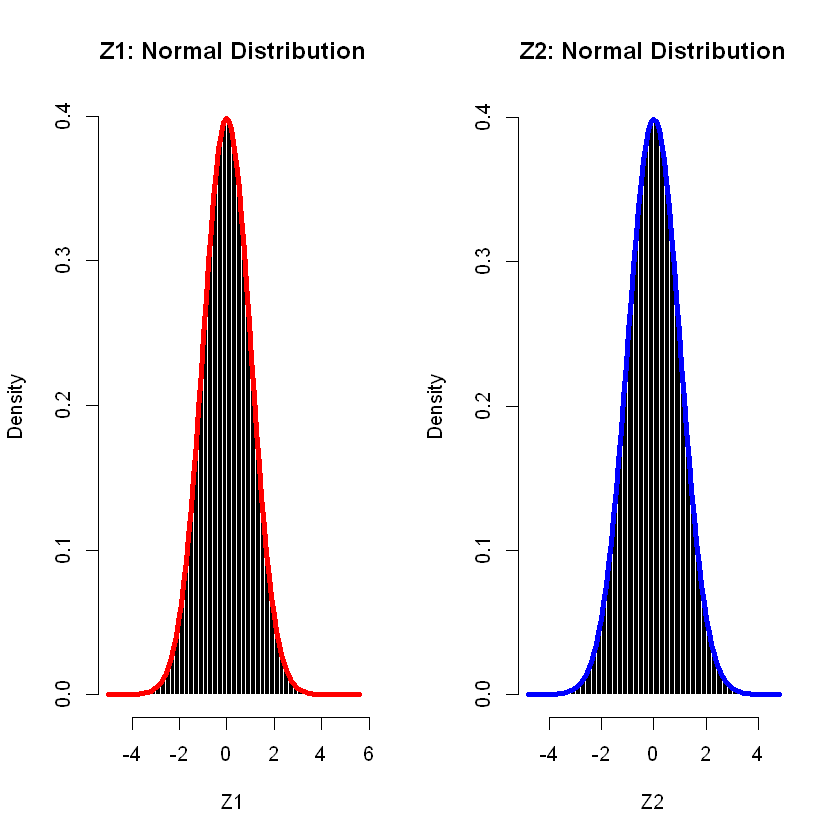

In [35]:
n <- 1000000
U1 <- runif(n, 0, 1)
U2 <- runif(n, 0, 1)
R <- sqrt(-2 * log(U1))
T <- 2 * pi * U2 
Z1 <- R * cos(T)
Z2 <- R * sin(T)
normal_density <- function(x) {
  (1 / sqrt(2 * pi)) * exp(-x^2 / 2)
}
par(bg = "white", mfrow = c(1, 2))
hist(Z1, breaks = 50, probability = TRUE, col = "black", border = "white", 
     main = "Z1: Normal Distribution", xlab = "Z1", ylab = "Density")
curve(normal_density(x), add = TRUE, col = "red", lwd = 4)
hist(Z2, breaks = 50, probability = TRUE, col = "black", border = "white", 
     main = "Z2: Normal Distribution", xlab = "Z2", ylab = "Density")
curve(normal_density(x), add = TRUE, col = "blue", lwd = 4)


Considering the two plots, we can conclude that the Box-Muller distribution correctly transformed the uniform distribution into a standard normal distribution.

THE END!!!